In [1]:
import ast
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('data_jobs.csv')

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

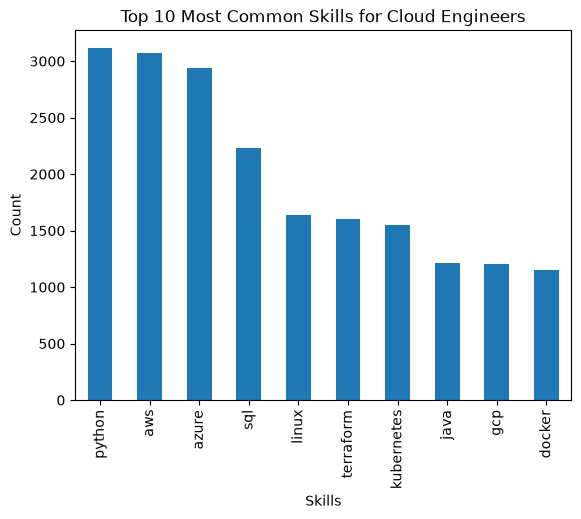

In [8]:
df_CE = df[df['job_title_short'] == 'Cloud Engineer'].copy()
df_exploded = df_CE.explode('job_skills')

df_exploded.groupby('job_skills').size().sort_values(ascending=False).head(10).plot(kind='bar')
plt.xlabel('Skills')
plt.ylabel('Count')
plt.title('Top 10 Most Common Skills for Cloud Engineers')
plt.show()


In [9]:
df_exploded = df.explode('job_skills')

In [14]:
df_exploded.pivot_table(values='salary_year_avg', index='job_skills', aggfunc='mean').sort_values(by='salary_year_avg', ascending=False).head()


,salary_year_avg
job_skills,
debian,196500.000000
ringcentral,182500.000000
lua,170500.000000
mongo,169526.929749
dplyr,160667.210526


In [27]:
df_exploded.pivot_table(values='job_skills', index='job_title_short', aggfunc='nunique').rename(columns={'job_skills':'num_unique_skills'}).head()

,num_unique_skills
job_title_short,
Business Analyst,223
Cloud Engineer,213
Data Analyst,235
Data Engineer,239
Data Scientist,237
